# EDA v3: cleaning and exploration

Raw files are in data/raw, one file per variable per year, covering all of BC. This notebook cuts them down to the Lower Mainland and the columns we use, and saves clean tables to data/processed.

## 1. Initial setup and raw data checks

This section mounts Google Drive, sets up the paths to our raw and processed data directories, and checks the raw NO2 files across all study years. It ensures that data ranges are complete and identifies any stations with missing hourly rows.

In [1]:
from google.colab import drive
import glob
import os
import pandas as pd

drive.mount("/content/drive")

raw_dir = "/content/drive/MyDrive/DS_Proj_Group_7/data/raw"
out_dir = "/content/drive/MyDrive/DS_Proj_Group_7/data/processed"
os.makedirs(out_dir, exist_ok=True)

# study period, every step uses these years
years = range(2015, 2025)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 1.1 Check the NO2 files

Before combining years, make sure every year's file looks the same - same region name, same units, and one row per station per hour.

In [2]:
for year in years:
    f = os.path.join(raw_dir, f"{year}_NO2.csv")
    if not os.path.exists(f):
        print(year, "not downloaded yet")
        continue

    df = pd.read_csv(f, usecols=["EMS_ID", "UNIT", "REGION"], dtype={"EMS_ID": str}, encoding="latin-1", low_memory=False)
    # if this finds 0 stations, the region name is spelled differently that year
    lm = df[df["REGION"] == "02 - Lower Mainland"]

    # a full year has one row per hour, so a complete station has this many rows
    hours = 8784 if year % 4 == 0 else 8760
    rows = lm.groupby("EMS_ID").size()
    odd = rows[rows != hours]

    print(year)
    print("  units:", list(lm["UNIT"].unique()))
    print("  Lower Mainland stations:", len(rows))
    print(f"  stations without exactly {hours} rows:", odd.to_dict() if len(odd) else "none")

2015
  units: ['ppb']
  Lower Mainland stations: 29
  stations without exactly 8760 rows: {'0310172': 8352, 'E222778': 8425, 'E304570': 360}
2016
  units: ['ppb']
  Lower Mainland stations: 28
  stations without exactly 8784 rows: none
2017
  units: ['ppb']
  Lower Mainland stations: 28
  stations without exactly 8760 rows: none
2018
  units: ['ppb']
  Lower Mainland stations: 29
  stations without exactly 8760 rows: {'0220204': 744, '0220205': 8017}
2019
  units: ['ppb']
  Lower Mainland stations: 28
  stations without exactly 8760 rows: {'0220205': 6923}
2020
  units: ['ppb']
  Lower Mainland stations: 27
  stations without exactly 8784 rows: {'E222778': 8477}
2021
  units: ['ppb']
  Lower Mainland stations: 28
  stations without exactly 8760 rows: {'E222778': 8733}
2022
  units: ['ppb']
  Lower Mainland stations: 28
  stations without exactly 8760 rows: none
2023
  units: ['ppb']
  Lower Mainland stations: 28
  stations without exactly 8760 rows: none
2024
  units: ['ppb']
  Lower M

**Found so far (2015-2019, 2024):** the region name is the same every year, NO2 is always in ppb, and no station has more rows than hours in the year, so there are no duplicate instruments. A few stations are missing rows in 2015, 2018 and 2019.

## 2. Timestamp parsing and time zone conversions

This section analyzes how timestamps are structured in the raw files using a sample station from 2024. It verifies that the raw date/time ignores daylight saving (fixed PST) and implements a robust transformation to local Vancouver time.

### 2.1 Figure out the timestamps

DATE_PST is supposed to be fixed PST (UTC-8, no daylight saving) and mark the end of each hour. Checked on one station (Abbotsford A Columbia Street) in 2024.

In [3]:
df = pd.read_csv(os.path.join(raw_dir, "2024_NO2.csv"), usecols=["DATE_PST", "DATE", "TIME", "EMS_ID"], dtype=str, encoding="latin-1")
station = df[df["EMS_ID"] == "E289309"].copy()

# DATE_PST is the end of the hour, so subtract 1 hour to get the start,
# then switch from fixed PST to Vancouver time, which handles daylight saving.
# "Etc/GMT+8" means UTC-8, the sign is backwards in this naming
station["start_local"] = (pd.to_datetime(station["DATE_PST"]) - pd.Timedelta(hours=1)).dt.tz_localize("Etc/GMT+8").dt.tz_convert("America/Vancouver")

print("how the last hour of the day (TIME 24:00) is written in DATE_PST:")
print(station[station["TIME"] == "24:00"][["DATE", "TIME", "DATE_PST"]].head(2))

print("\nrows on the two daylight saving days (24 each means DATE_PST ignores daylight saving):")
print(station.groupby("DATE").size()[["2024-03-10", "2024-11-03"]])

print("\nMarch 10, clocks jump forward, so 2am local should be skipped:")
print(station[station["DATE"] == "2024-03-10"][["DATE_PST", "start_local"]].head(5))

print("\nJuly 1, summer time, so the offset should be -07:00:")
print(station[station["DATE"] == "2024-07-01"][["DATE_PST", "start_local"]].head(3))

how the last hour of the day (TIME 24:00) is written in DATE_PST:
          DATE   TIME          DATE_PST
23  2024-01-01  24:00  2024-01-02 00:00
47  2024-01-02  24:00  2024-01-03 00:00

rows on the two daylight saving days (24 each means DATE_PST ignores daylight saving):
DATE
2024-03-10    24
2024-11-03    24
dtype: int64

March 10, clocks jump forward, so 2am local should be skipped:
              DATE_PST               start_local
1656  2024-03-10 01:00 2024-03-10 00:00:00-08:00
1657  2024-03-10 02:00 2024-03-10 01:00:00-08:00
1658  2024-03-10 03:00 2024-03-10 03:00:00-07:00
1659  2024-03-10 04:00 2024-03-10 04:00:00-07:00
1660  2024-03-10 05:00 2024-03-10 05:00:00-07:00

July 1, summer time, so the offset should be -07:00:
              DATE_PST               start_local
4368  2024-07-01 01:00 2024-07-01 01:00:00-07:00
4369  2024-07-01 02:00 2024-07-01 02:00:00-07:00
4370  2024-07-01 03:00 2024-07-01 03:00:00-07:00


**Found:** TIME 24:00 shows up in DATE_PST as 00:00 the next day. Both daylight saving days have 24 rows, so DATE_PST is fixed UTC-8. After converting, March 10 skips 2am and July 1 is at -07:00.

So for every table: local start of hour = DATE_PST minus 1 hour, converted from UTC-8 to Vancouver time.

## 3. Compiling and cleaning the NO2 table

This section reads the raw NO2 data for all available years, keeps only the Lower Mainland region, adjusts timestamps to local start-of-hour, and saves the consolidated table to a Parquet file.

### 3.1 Build NO2 table

Every later step only needs station, local hour and NO2 value. Read each year once, keep the Lower Mainland, drop hours with no reading, fix the time, and save it all as one file.

In [4]:
parts = []

for year in years:
    f = os.path.join(raw_dir, f"{year}_NO2.csv")
    if not os.path.exists(f):
        print(year, "not downloaded yet")
        continue

    df = pd.read_csv(f, usecols=["DATE_PST", "EMS_ID", "STATION_NAME", "RAW_VALUE", "REGION"], dtype={"EMS_ID": str}, encoding="latin-1", low_memory=False)

    # keep the Lower Mainland and drop hours with no reading
    df = df[df["REGION"] == "02 - Lower Mainland"].dropna(subset=["RAW_VALUE"])

    # same time fix as step 2
    df["start_local"] = (pd.to_datetime(df["DATE_PST"]) - pd.Timedelta(hours=1)).dt.tz_localize("Etc/GMT+8").dt.tz_convert("America/Vancouver")
    df["year"] = year
    df = df.rename(columns={"RAW_VALUE": "no2"})
    parts.append(df[["EMS_ID", "STATION_NAME", "year", "start_local", "no2"]])

    n_stations = df["EMS_ID"].nunique()
    n_negative = (df["no2"] < 0).sum()
    print(f"{year}: {n_stations} stations, {len(df)} hours with a reading, {n_negative} readings below zero")

no2 = pd.concat(parts, ignore_index=True)
no2.to_parquet(os.path.join(out_dir, "no2_lm.parquet"))

print(f"\nsaved no2_lm.parquet with {len(no2)} rows. first few:")
print(no2.head(3))

2015: 29 stations, 223894 hours with a reading, 1 readings below zero
2016: 28 stations, 239074 hours with a reading, 16 readings below zero
2017: 28 stations, 234913 hours with a reading, 56 readings below zero
2018: 29 stations, 241577 hours with a reading, 9 readings below zero
2019: 28 stations, 239799 hours with a reading, 19 readings below zero
2020: 27 stations, 232739 hours with a reading, 2 readings below zero
2021: 28 stations, 240350 hours with a reading, 13 readings below zero
2022: 28 stations, 238919 hours with a reading, 0 readings below zero
2023: 28 stations, 238867 hours with a reading, 0 readings below zero
2024: 28 stations, 235380 hours with a reading, 0 readings below zero

saved no2_lm.parquet with 2365512 rows. first few:
    EMS_ID             STATION_NAME  year               start_local       no2
0  0310174  Vancouver Robson Square  2015 2015-01-01 00:00:00-08:00  22.62045
1  0310174  Vancouver Robson Square  2015 2015-01-01 01:00:00-08:00  20.54405
2  0310174

## 4. Data coverage analysis

This section loads the cleaned NO2 master table and calculates the percentage of annual hourly readings available for each station. This allows us to assess data quality and filter out stations with incomplete coverage.

In [5]:
# load the clean NO2 table saved in step 3
no2 = pd.read_parquet(os.path.join(out_dir, "no2_lm.parquet"))

# hours in each year (2016, 2020 and 2024 are leap years)
hours_in_year = pd.Series({y: 8784 if y % 4 == 0 else 8760 for y in years})

# count hours with a reading for each station and year, then turn that into a percent
counts = no2.groupby(["STATION_NAME", "year"]).size().unstack()
coverage = (counts / hours_in_year * 100).round(0)

print("percent of hours with an NO2 reading, by station (rows) and year (columns)")
print(coverage.to_string())

percent of hours with an NO2 reading, by station (rows) and year (columns)
year                                2015  2016  2017   2018   2019   2020   2021   2022   2023   2024
STATION_NAME                                                                                         
Abbotsford A Columbia Street        95.0  97.0  91.0   98.0   97.0   99.0   99.0  100.0  100.0  100.0
Abbotsford Central                  97.0  97.0  97.0   98.0   99.0   99.0   99.0  100.0  100.0   99.0
Agassiz Centennial Park              NaN   NaN   NaN    NaN    NaN    NaN    NaN    NaN    NaN   99.0
Agassiz Municipal Hall              98.0  98.0  98.0   99.0   99.0   99.0  100.0   99.0  100.0    NaN
Burnaby Kensington Park             97.0  98.0  98.0  100.0   98.0   93.0   99.0  100.0   99.0   98.0
Burnaby Mountain                    98.0  97.0  98.0   99.0   99.0  100.0  100.0   99.0   99.0   94.0
Burnaby South                       98.0  95.0  98.0   99.0   98.0   99.0   99.0   99.0  100.0  100.0
Chilliw

## 5. Weekday vs. weekend hourly NO2 trends

This section isolates pre-COVID years (2016-2019) to compare average NO2 levels by local hour between weekdays and weekends/holidays. It plots these hourly patterns for Clark Drive and Tsawwassen to visualize traffic-related rush-hour peaks.

holidays treated as weekend: ['British Columbia Day', 'Canada Day', 'Canada Day (observed)', 'Christmas Day', 'Christmas Day (observed)', 'Family Day', 'Good Friday', 'Labor Day', "New Year's Day", "New Year's Day (observed)", 'Remembrance Day', 'Thanksgiving Day', 'Victoria Day']

mean NO2 (ppb) by local hour, 2016-2019
series  Clark Drive, weekday  Clark Drive, weekend/holiday  Tsawwassen, weekday  Tsawwassen, weekend/holiday
hour                                                                                                        
0                       19.5                          19.4                  7.6                          7.4
1                       17.9                          17.6                  7.3                          7.1
2                       16.8                          16.6                  7.2                          6.9
3                       16.0                          15.7                  7.0                          6.7
4                      

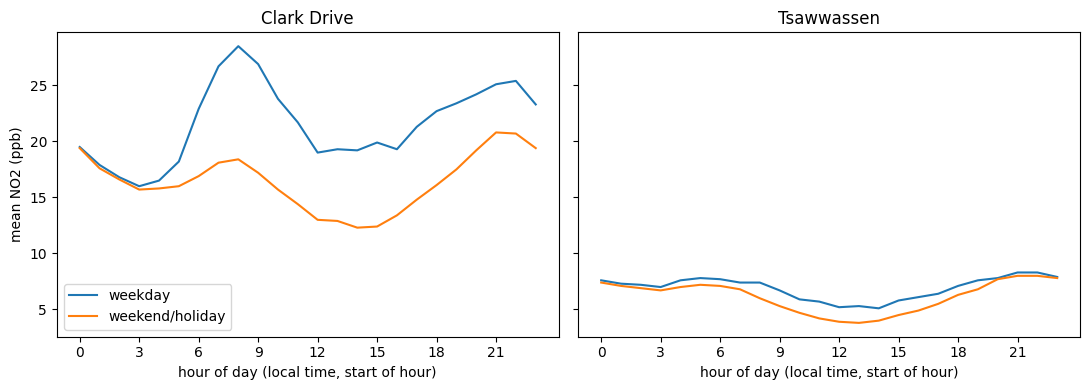

In [6]:
import holidays
import matplotlib.pyplot as plt

tsa_id = no2.loc[no2["STATION_NAME"] == "Tsawwassen", "EMS_ID"].iloc[0]
stations = {"E316370": "Clark Drive", tsa_id: "Tsawwassen"}

# normal period, pre-COVID, for the two comparison stations
normal = no2[no2["year"].between(2016, 2019) & no2["EMS_ID"].isin(stations.keys())].copy()

# local date and hour of each reading
normal["date"] = normal["start_local"].dt.date
normal["hour" ] = normal["start_local"].dt.hour

# weekday = Monday to Friday and not a BC stat holiday, everything else is weekend/holiday
bc_holidays = holidays.Canada(subdiv="BC", years=range(2016, 2020))
print("holidays treated as weekend:", sorted(set(bc_holidays.values())))
is_weekday = (normal["start_local"].dt.dayofweek < 5) & ~normal["date"].isin(list(bc_holidays.keys()))
normal["day_type"] = is_weekday.map({True: "weekday", False: "weekend/holiday"})

# average NO2 for each hour of the day, per station and day type
normal["series"] = normal["EMS_ID"].map(stations) + ", " + normal["day_type"]
means = normal.groupby(["hour", "series"])["no2"].mean().unstack().round(1)
print("\nmean NO2 (ppb) by local hour, 2016-2019")
print(means.to_string())

# one panel per station, same y axis so the two stations can be compared
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, name in zip(axes, stations.values()):
    ax.plot(means.index, means[f"{name}, weekday"], label="weekday")
    ax.plot(means.index, means[f"{name}, weekend/holiday"], label="weekend/holiday")
    ax.set_title(name)
    ax.set_xlabel("hour of day (local time, start of hour)")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("mean NO2 (ppb)")
axes[0].legend()
plt.tight_layout()
plt.show()

In [7]:
# weekday vs weekend 7-11 am NO2 at every station, 2016-2019
lm = no2[no2["year"].between(2016, 2019)].copy()
lm["date"] = lm["start_local"].dt.date
lm["hour"] = lm["start_local"].dt.hour
lm = lm[lm["hour"].between(7, 10)]

is_weekday = (lm["start_local"].dt.dayofweek < 5) & ~lm["date"].isin(list(bc_holidays.keys()))
lm["day_type"] = is_weekday.map({True: "weekday", False: "weekend"})

table = lm.groupby(["STATION_NAME", "day_type"])["no2"].mean().unstack()
table["weekday bump %"] = (table["weekday"] / table["weekend"] - 1) * 100
print(table.round(1).sort_values("weekday bump %").to_string())

day_type                            weekday  weekend  weekday bump %
STATION_NAME                                                        
Tsawwassen                              6.8      5.7            20.0
Hope Airport                            4.7      3.8            23.7
Langdale Elementary                     6.2      4.9            27.7
Vancouver Robson Square                20.0     15.5            29.1
Powell River Cranberry Lake             2.3      1.8            31.2
North Vancouver Mahon Park             15.3     11.2            37.3
Chilliwack Airport                      8.9      6.4            39.3
Powell River Wildwood                   2.8      2.0            42.3
Vancouver International Airport #2     17.7     12.4            42.4
Richmond South                         15.2     10.7            42.5
Pitt Meadows Meadowlands School        10.2      7.1            42.5
Agassiz Municipal Hall                  8.6      6.0            43.9
North Delta                       

## 6. Baseline prediction


In [8]:
import numpy as np

# baseline: repeat the last 24 observed hours for each of the next 3 days
# for a target hour on day d ahead (d = 1, 2, 3), the prediction is the value 24*d hours earlier
rows = []

for ems_id, name in stations.items():
    st_data = no2[(no2["EMS_ID"] == ems_id) & no2["year"].between(2016, 2019)]
    # index by UTC so every step is exactly one hour, even across daylight saving changes
    s = st_data.set_index(st_data["start_local"].dt.tz_convert("UTC"))["no2"]

    # fill in every hour so shifting by 24 rows really means 24 hours (missing hours stay blank)
    full_hours = pd.date_range(s.index.min(), s.index.max(), freq="h")
    s = s.reindex(full_hours)

    for d in [1, 2, 3]:
        err = (s - s.shift(24 * d)).dropna()
        rows.append({"station": name, "day ahead": d, "hours scored": len(err), "RMSE": np.sqrt((err ** 2).mean()), "MAE": err.abs().mean()})

baseline = pd.DataFrame(rows)
print("baseline (last observed 24 hours repeated), 2016-2019, NO2 in ppb")
print(baseline.round(2).to_string(index=False))

baseline (last observed 24 hours repeated), 2016-2019, NO2 in ppb
    station  day ahead  hours scored  RMSE  MAE
Clark Drive          1         33189 10.22 7.79
Clark Drive          2         32988 11.42 8.92
Clark Drive          3         33061 11.82 9.26
 Tsawwassen          1         33920  6.85 4.67
 Tsawwassen          2         33850  7.51 5.22
 Tsawwassen          3         34026  7.77 5.37


## 7. Morning rush hour bootstrap significance testing

This section calculates the 7-11 AM weekday morning rush-hour NO2 'bump' relative to weekends for both comparison stations. It uses bootstrapping to generate 95% confidence intervals to evaluate statistical significance.

In [9]:
# morning rush window: 7 to 11 am (hours 7, 8, 9, 10)
morning = normal[normal["hour"].between(7, 10)]

# one value per station per day: average over the window, only days with all 4 hours
daily = morning.groupby(["EMS_ID", "date", "day_type"])["no2"].agg(["mean", "count"]).reset_index()
daily = daily[daily["count"] == 4].copy()
daily["month"] = pd.to_datetime(daily["date"]).dt.to_period("M")

rng = np.random.default_rng(42)

for ems_id, name in stations.items():
    d = daily[daily["EMS_ID"] == ems_id]

    # per month: sum and number of weekday values, and the same for weekend/holiday days
    by_month = d.groupby(["month", "day_type"])["mean"].agg(["sum", "count"]).unstack("day_type", fill_value=0)
    wd_sum = by_month[("sum", "weekday")].to_numpy()
    wd_n = by_month[("count", "weekday")].to_numpy()
    we_sum = by_month[("sum", "weekend/holiday")].to_numpy()
    we_n = by_month[("count", "weekend/holiday")].to_numpy()

    wd_mean = wd_sum.sum() / wd_n.sum()
    we_mean = we_sum.sum() / we_n.sum()
    diff = wd_mean - we_mean
    pct = diff / we_mean * 100

    # resample whole months 2000 times: draw as many months as there are, with replacement,
    # and keep every day in them, so weekdays and weekends from the same weather stay together
    n_months = len(by_month)
    boot_diff = []
    boot_pct = []
    for _ in range(2000):
        pick = rng.integers(0, n_months, n_months)
        wd_s = wd_sum[pick].sum() / wd_n[pick].sum()
        we_s = we_sum[pick].sum() / we_n[pick].sum()
        boot_diff.append(wd_s - we_s)
        boot_pct.append((wd_s - we_s) / we_s * 100)
    low, high = np.percentile(boot_diff, [2.5, 97.5])
    low_pct, high_pct = np.percentile(boot_pct, [2.5, 97.5])

    print(name)
    print(f"days: {wd_n.sum()} weekdays, {we_n.sum()} weekend/holiday days, in {n_months} months")
    print(f"7-11 am average: weekday {wd_mean:.1f} ppb, weekend/holiday {we_mean:.1f} ppb")
    print(f"weekday minus weekend: {diff:.1f} ppb (95% CI {low:.1f} to {high:.1f})")
    print(f"as a percent: {pct:.0f}% higher on weekdays (95% CI {low_pct:.0f}% to {high_pct:.0f}%)")

Clark Drive
days: 928 weekdays, 440 weekend/holiday days, in 48 months
7-11 am average: weekday 26.4 ppb, weekend/holiday 17.4 ppb
weekday minus weekend: 9.0 ppb (95% CI 8.2 to 9.9)
as a percent: 52% higher on weekdays (95% CI 46% to 59%)
Tsawwassen
days: 960 weekdays, 453 weekend/holiday days, in 48 months
7-11 am average: weekday 6.8 ppb, weekend/holiday 5.7 ppb
weekday minus weekend: 1.2 ppb (95% CI 0.7 to 1.6)
as a percent: 20% higher on weekdays (95% CI 12% to 30%)


## 8. Station pair comparison and increment analysis

This section isolates days where both Clark Drive and Tsawwassen have valid daily readings to compute the absolute and relative differences between near-road and urban background environments. It applies bootstrapping to estimate the confidence interval of this near-road increment.

In [10]:
# daily average at each station, only days with at least 18 of 24 hours
day_stats = normal.groupby(["EMS_ID", "date"])["no2"].agg(["mean", "count"]).reset_index()
day_stats = day_stats[day_stats["count"] >= 18]

# the two stations side by side, only days where both have a value
paired = day_stats.pivot(index="date", columns="EMS_ID", values="mean").dropna()
near_road = paired["E316370"].to_numpy()
background = paired[tsa_id].to_numpy()
diff = near_road - background

# resample whole days 2000 times
boot_diff = []
boot_ratio = []
for _ in range(2000):
    idx = rng.integers(0, len(diff), len(diff))
    boot_diff.append(diff[idx].mean())
    boot_ratio.append(near_road[idx].mean() / background[idx].mean())
low, high = np.percentile(boot_diff, [2.5, 97.5])
low_r, high_r = np.percentile(boot_ratio, [2.5, 97.5])

print(f"days with data at both stations (2016-2019): {len(diff)}")
print(f"daily average: Clark Drive {near_road.mean():.1f} ppb, Tsawwassen {background.mean():.1f} ppb")
print(f"near-road increment: {diff.mean():.1f} ppb (95% CI {low:.1f} to {high:.1f})")
print(f"Clark Drive is {near_road.mean() / background.mean():.2f} times the background (95% CI {low_r:.2f} to {high_r:.2f})")

days with data at both stations (2016-2019): 1405
daily average: Clark Drive 20.0 ppb, Tsawwassen 6.6 ppb
near-road increment: 13.3 ppb (95% CI 13.0 to 13.7)
Clark Drive is 3.01 times the background (95% CI 2.93 to 3.10)


## 9. Autocorrelation and temporal lag analysis

This section assesses the persistence of daily NO2 levels by calculating the autocorrelation for lags ranging from 1 to 14 days. It plots these correlation coefficients to observe weekly cycles and overall temporal dependency.

correlation of daily mean NO2 with the same station k days earlier, 2016-2019
            Clark Drive  Tsawwassen
lag (days)                         
1                  0.68        0.59
2                  0.48        0.34
3                  0.43        0.24
4                  0.41        0.23
5                  0.41        0.18
6                  0.50        0.20
7                  0.57        0.21
8                  0.50        0.21
9                  0.40        0.21
10                 0.38        0.20
11                 0.38        0.20
12                 0.40        0.17
13                 0.44        0.18
14                 0.51        0.18


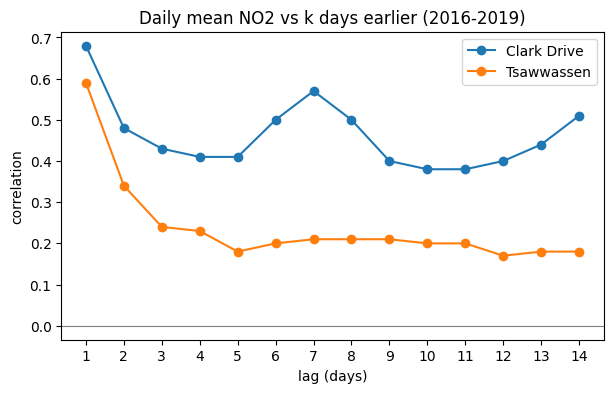

In [11]:
# daily average per station, only days with at least 18 of 24 hours
daily_avg = normal.groupby(["EMS_ID", "date"])["no2"].agg(["mean", "count"])
daily_avg = daily_avg[daily_avg["count"] >= 18]["mean"].unstack("EMS_ID")

# fill in every calendar day so "k days earlier" really means k days (missing days stay blank)
all_days = pd.date_range("2016-01-01", "2019-12-31").date
daily_avg = daily_avg.reindex(all_days)

# correlation between each day's NO2 and the same station k days earlier
lags = range(1, 15)
acf = pd.DataFrame({name: [daily_avg[ems_id].autocorr(lag) for lag in lags] for ems_id, name in stations.items()}, index=lags).round(2)
acf.index.name = "lag (days)"
print("correlation of daily mean NO2 with the same station k days earlier, 2016-2019")
print(acf.to_string())

acf.plot(marker="o", figsize=(7, 4))
plt.axhline(0, color="grey", linewidth=0.8)
plt.xticks(lags)
plt.xlabel("lag (days)")
plt.ylabel("correlation")
plt.title("Daily mean NO2 vs k days earlier (2016-2019)")
plt.show()

## 10. Spatial correlation and station distance analysis

This section measures the spatial relationships of daily NO2 levels across all 27 qualifying stations in the Lower Mainland. It computes the straight-line distance (haversine) between every station pair and analyzes how daily correlation decays as distance increases.

stations kept: 27
stations not in the station list: []

correlation of daily NO2 between station pairs, by distance apart
               count  mean   min   max
distance band                         
0-10 km           30  0.72  0.43  0.92
10-25 km          83  0.70  0.29  0.92
25-50 km          97  0.56  0.32  0.82
over 50 km       141  0.35 -0.01  0.71


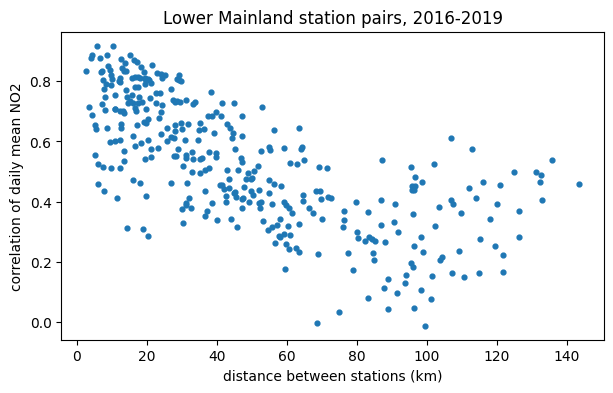

In [12]:
# daily average for every Lower Mainland station, 2016-2019, only days with at least 18 of 24 hours
lm = no2[no2["year"].between(2016, 2019)].copy()
lm["date"] = lm["start_local"].dt.date
lm_daily = lm.groupby(["EMS_ID", "date"])["no2"].agg(["mean", "count"])
lm_daily = lm_daily[lm_daily["count"] >= 18]["mean"].unstack("EMS_ID")

# keep stations with a value on at least 75% of the 1461 days
lm_daily = lm_daily.loc[:, lm_daily.count() >= 0.75 * 1461]
print("stations kept:", lm_daily.shape[1])

# station coordinates, joined on EMS_ID
st = pd.read_csv(os.path.join(raw_dir, "2024_bc_air_monitoring_stations.csv"), dtype={"EMS_ID": str}, encoding="latin-1")
st = st.drop_duplicates("EMS_ID").set_index("EMS_ID")
print("stations not in the station list:", [e for e in lm_daily.columns if e not in st.index])

# correlation of daily NO2 for every pair of stations (uses days both have)
corr = lm_daily.corr()

rows = []
ids = [e for e in lm_daily.columns if e in st.index]
for i, a in enumerate(ids):
    for b in ids[i + 1:]:
        lat1, lon1 = np.radians(st.loc[a, ["LAT", "LONG"]].astype(float))
        lat2, lon2 = np.radians(st.loc[b, ["LAT", "LONG"]].astype(float))
        # straight-line distance over the Earth's surface (haversine), in km
        h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
        km = 2 * 6371 * np.arcsin(np.sqrt(h))
        rows.append({"station_a": st.loc[a, "STATION_NAME"], "station_b": st.loc[b, "STATION_NAME"], "km": km, "corr": corr.loc[a, b]})
pairs = pd.DataFrame(rows)

# average correlation by distance band
pairs["distance band"] = pd.cut(pairs["km"], [0, 10, 25, 50, 200], labels=["0-10 km", "10-25 km", "25-50 km", "over 50 km"])
print("\ncorrelation of daily NO2 between station pairs, by distance apart")
print(pairs.groupby("distance band", observed=True)["corr"].agg(["count", "mean", "min", "max"]).round(2).to_string())

plt.figure(figsize=(7, 4))
plt.scatter(pairs["km"], pairs["corr"], s=12)
plt.xlabel("distance between stations (km)")
plt.ylabel("correlation of daily mean NO2")
plt.title("Lower Mainland station pairs, 2016-2019")
plt.show()

## 11. COVID-19 lockdown impact evaluation

This section evaluates the air quality impact of the spring 2020 COVID-19 lockdown by comparing average NO2 levels from March 16 to May 31 against the 2016-2019 baseline. It quantifies and visualizes the percentage drop in emissions at both selected stations.

mean NO2 (ppb), March 16 to May 31
EMS_ID  Tsawwassen  Clark Drive
year                           
2016           5.7         19.5
2017           5.2         18.6
2018           5.4         17.9
2019           5.5         17.2
2020           4.7         14.2

2020 compared with the 2016-2019 average:
  Clark Drive: 18.3 -> 14.2 ppb, -4.1 ppb (-22%)
  Tsawwassen: 5.5 -> 4.7 ppb, -0.8 ppb (-14%)


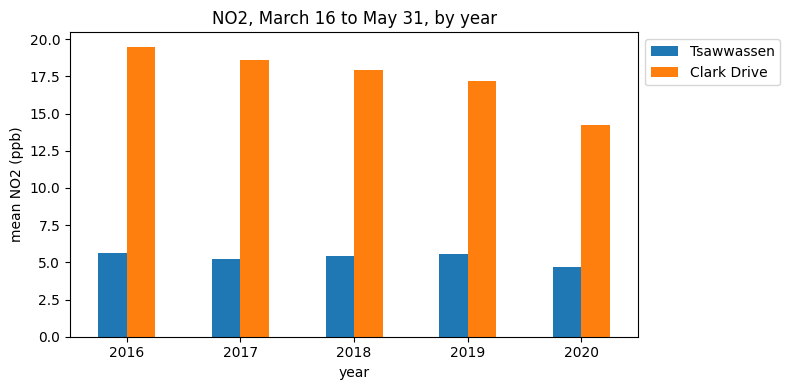

In [13]:
# lockdown window: March 16 to May 31, same dates in 2016-2019 for comparison
window = no2[no2["EMS_ID"].isin(stations.keys()) & no2["year"].between(2016, 2020)].copy()
month_day = window["start_local"].dt.strftime("%m-%d")
window = window[(month_day >= "03-16") & (month_day <= "05-31")]

# average NO2 in the window, one value per station per year
by_year = window.groupby(["year", "EMS_ID"])["no2"].mean().unstack("EMS_ID").rename(columns=stations)
print("mean NO2 (ppb), March 16 to May 31")
print(by_year.round(1).to_string())

before = by_year.loc[2016:2019].mean()
during = by_year.loc[2020]
print("\n2020 compared with the 2016-2019 average:")
for name in stations.values():
    change = during[name] - before[name]
    print(f"  {name}: {before[name]:.1f} -> {during[name]:.1f} ppb, {change:+.1f} ppb ({change / before[name] * 100:+.0f}%)")

by_year.plot(kind="bar", figsize=(8, 4))
plt.ylabel("mean NO2 (ppb)")
plt.title("NO2, March 16 to May 31, by year")
plt.xticks(rotation=0)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

mean NO2 (ppb), March 16 to May 31
EMS_ID  Tsawwassen  Clark Drive
year                           
2016           5.7         19.5
2017           5.2         18.6
2018           5.4         17.9
2019           5.5         17.2
2020           4.7         14.2

2020 compared with what the 2016-2019 trend predicts for 2020:
  Clark Drive: trend -0.75 ppb/year, expected 16.4, actual 14.2, -2.2 ppb (-13%)
    for reference, vs the plain 2016-2019 average (18.3): -22%
  Tsawwassen: trend -0.01 ppb/year, expected 5.4, actual 4.7, -0.7 ppb (-13%)
    for reference, vs the plain 2016-2019 average (5.5): -14%


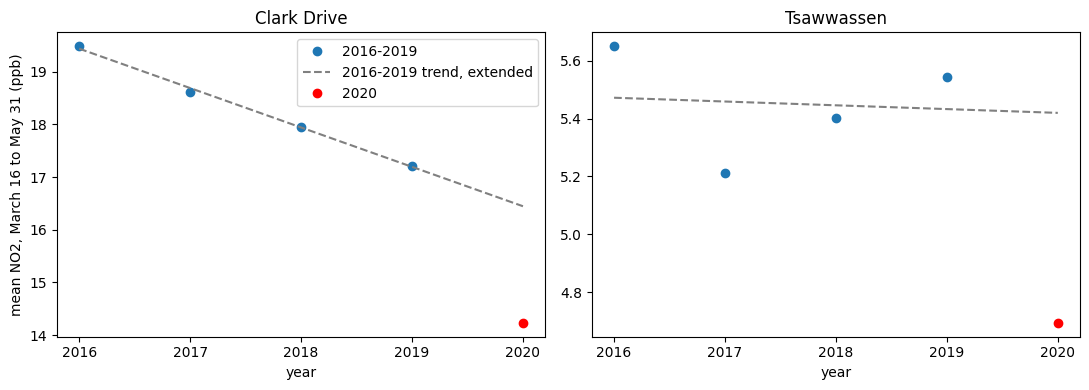

In [14]:
# lockdown window: March 16 to May 31, same dates in 2016-2019 for comparison
window = no2[no2["EMS_ID"].isin(stations.keys()) & no2["year"].between(2016, 2020)].copy()
month_day = window["start_local"].dt.strftime("%m-%d")
window = window[(month_day >= "03-16") & (month_day <= "05-31")]

# average NO2 in the window, one value per station per year
by_year = window.groupby(["year", "EMS_ID"])["no2"].mean().unstack("EMS_ID").rename(columns=stations)
print("mean NO2 (ppb), March 16 to May 31")
print(by_year.round(1).to_string())

# expected 2020 level without a lockdown: fit a straight line through 2016-2019 and extend it to 2020
pre = by_year.loc[2016:2019]
fits = {}
print("\n2020 compared with what the 2016-2019 trend predicts for 2020:")
for name in stations.values():
    slope, intercept = np.polyfit(pre.index, pre[name], 1)
    fits[name] = (slope, intercept)
    expected = slope * 2020 + intercept
    actual = by_year.loc[2020, name]
    change = actual - expected
    print(f"  {name}: trend {slope:+.2f} ppb/year, expected {expected:.1f}, actual {actual:.1f}, {change:+.1f} ppb ({change / expected * 100:+.0f}%)")
    print(f"    for reference, vs the plain 2016-2019 average ({pre[name].mean():.1f}): {(actual / pre[name].mean() - 1) * 100:+.0f}%")

# the gap between the dashed line and the red point at 2020 is the lockdown effect
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, stations.values()):
    slope, intercept = fits[name]
    ax.plot(pre.index, pre[name], "o", label="2016-2019")
    ax.plot([2016, 2020], [slope * 2016 + intercept, slope * 2020 + intercept], "--", color="grey", label="2016-2019 trend, extended")
    ax.plot(2020, by_year.loc[2020, name], "o", color="red", label="2020")
    ax.set_title(name)
    ax.set_xticks(range(2016, 2021))
    ax.set_xlabel("year")
axes[0].set_ylabel("mean NO2, March 16 to May 31 (ppb)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 12. Weather metadata extraction and coverage check

This section processes local meteorological variables (temperature, humidity, and wind velocity) across our study period. It resolves duplicate instrument readings and evaluates data coverage for the Lower Mainland stations.

In [15]:
weather_vars = ["TEMP_MEAN", "WSPD_SCLR", "WDIR_VECT", "HUMIDITY", "PRECIP", "PRESSURE"]
parts = []
missing = []

for var in weather_vars:
    for year in years:
        f = os.path.join(raw_dir, f"{year}_{var}.csv")
        if not os.path.exists(f):
            missing.append(f"{year}_{var}")
            continue
        df = pd.read_csv(f, usecols=["DATE_PST", "EMS_ID", "STATION_NAME", "RAW_VALUE", "UNIT", "REGION"], dtype={"EMS_ID": str}, encoding="latin-1", low_memory=False)
        df["RAW_VALUE"] = pd.to_numeric(df["RAW_VALUE"], errors="coerce")
        # keep the Lower Mainland and drop hours with no reading
        df = df[df["REGION"] == "02 - Lower Mainland"].dropna(subset=["RAW_VALUE"])
        # same time fix as NO2
        df["start_local"] = (pd.to_datetime(df["DATE_PST"]) - pd.Timedelta(hours=1)).dt.tz_localize("Etc/GMT+8").dt.tz_convert("America/Vancouver")
        df["year"] = year
        df["variable"] = var
        parts.append(df[["EMS_ID", "STATION_NAME", "year", "start_local", "variable", "RAW_VALUE", "UNIT"]])

weather = pd.concat(parts, ignore_index=True).rename(columns={"RAW_VALUE": "value"})
print("files not downloaded yet:", missing if missing else "none")

print("\nunits found for each variable:")
print(weather.groupby("variable")["UNIT"].unique().to_string())

# more than one reading for the same station, variable and hour means more than one instrument
dup = weather.duplicated(["EMS_ID", "variable", "start_local"])
print("\nduplicate readings by variable:")
print(weather[dup].groupby("variable").size().to_string() if dup.any() else "none")
weather = weather[~dup]

# coverage: % of hours with a value, per variable, station and year
w_counts = weather.groupby(["variable", "EMS_ID", "year"]).size().unstack("year")
w_hours = pd.Series({y: 8784 if y % 4 == 0 else 8760 for y in w_counts.columns})
w_coverage = w_counts / w_hours * 100

print("\nnumber of Lower Mainland stations with at least 75% of hours, by variable and year")
print((w_coverage >= 75).groupby(level="variable").sum().to_string())

# the two comparison stations, 2016-2019 combined (1461 days x 24 hours = 35064 hours)
sub = weather[weather["EMS_ID"].isin(stations.keys()) & weather["year"].between(2016, 2019)]
two = sub.groupby(["variable", "EMS_ID"]).size().unstack("EMS_ID").reindex(columns=list(stations.keys()))
print("\nClark Drive and Tsawwassen, % of hours with a value, 2016-2019")
print((two / 35064 * 100).round(0).rename(columns=stations).to_string())

weather.to_parquet(os.path.join(out_dir, "weather_lm.parquet"))
print(f"\nsaved weather_lm.parquet with {len(weather)} rows")

files not downloaded yet: none

units found for each variable:
variable
HUMIDITY     [% RH]
TEMP_MEAN      [°C]
WDIR_VECT    [Deg.]
WSPD_SCLR     [m/s]

duplicate readings by variable:
none

number of Lower Mainland stations with at least 75% of hours, by variable and year
year       2015  2016  2017  2018  2019  2020  2021  2022  2023  2024
variable                                                             
HUMIDITY      4     2     3     3     4     4     3     3     2     2
TEMP_MEAN     5     4     4     4     5     5     4     4     3     3
WDIR_VECT     5     4     4     4     5     5     4     4     3     2
WSPD_SCLR     5     4     4     4     5     5     4     4     3     2

Clark Drive and Tsawwassen, % of hours with a value, 2016-2019
Empty DataFrame
Columns: [Clark Drive, Tsawwassen]
Index: []

saved weather_lm.parquet with 1345325 rows


In [16]:
import requests

url = "https://climate.weather.gc.ca/climate_data/bulk_data_e.html?format=csv&stationID={}&Year={}&Month={}&timeframe=1"

# one month per case, printed as raw text before any parsing
# Tsawwassen is tried in 2016 (possibly before the station existed) and 2021 (should have data)
tests = [("YVR", 51442, 2016), ("Tsawwassen Ferry", 50228, 2016), ("Tsawwassen Ferry", 50228, 2021)]

for name, wx_id, year in tests:
    r = requests.get(url.format(wx_id, year, 1), timeout=30)
    print(f"=== {name}, January {year}: status {r.status_code}, content type {r.headers.get('Content-Type')} ===")
    print(r.text[:500])
    print()

=== YVR, January 2016: status 200, content type text/html; charset=UTF-8 ===
<!DOCTYPE html>
<html class="no-js" lang="en" dir="ltr">
<head>
<meta charset="utf-8">
<!-- Web Experience Toolkit (WET) / Boîte à outils de l'expérience Web (BOEW) wet-boew.github.io/wet-boew/License-en.html / wet-boew.github.io/wet-boew/Licence-fr.html -->
<title>Historical Data - Climate - Environment and Climate Change Canada</title>
<meta content="width=device-width, initial-scale=1" name="viewport">
<meta name="description" content="historical climate data web site is a gateway to i

=== Tsawwassen Ferry, January 2016: status 200, content type text/html; charset=UTF-8 ===
<!DOCTYPE html>
<html class="no-js" lang="en" dir="ltr">
<head>
<meta charset="utf-8">
<!-- Web Experience Toolkit (WET) / Boîte à outils de l'expérience Web (BOEW) wet-boew.github.io/wet-boew/License-en.html / wet-boew.github.io/wet-boew/Licence-fr.html -->
<title>Historical Data - Climate - Environment and Climate Change Canada</title

In [17]:
# ECCC's official data API, YVR (climate ID 1108395), January 2016, first 3 hours
api = "https://api.weather.gc.ca/collections/climate-hourly/items?CLIMATE_IDENTIFIER=1108395&LOCAL_YEAR=2016&LOCAL_MONTH=1&limit=3&f=json"
r = requests.get(api, timeout=30)
print("status", r.status_code)
if r.ok:
    data = r.json()
    print("hours matched:", data.get("numberMatched"))
    for f in data.get("features", []):
        p = f["properties"]
        print(p["UTC_DATE"], "temp", p["TEMP"], "rh", p["RELATIVE_HUMIDITY"], "wind", p["WIND_SPEED"], p["WIND_DIRECTION"])
else:
    print(r.text[:500])

status 200
hours matched: 744
2016-01-01T11:00:00 temp -4.4 rh 95 wind 7 10
2016-01-01T08:00:00 temp -1.8 rh 91 wind 4 8
2016-01-01T09:00:00 temp -3.4 rh 91 wind 8 8


In [18]:
# hourly weather for YVR (climate ID 1108395) from ECCC's data API, one request per month
api = "https://api.weather.gc.ca/collections/climate-hourly/items?CLIMATE_IDENTIFIER=1108395&LOCAL_YEAR={}&LOCAL_MONTH={}&limit=1000&f=json"
fields = {"UTC_DATE": "utc", "TEMP": "temp", "RELATIVE_HUMIDITY": "rh", "WIND_DIRECTION": "wdir", "WIND_SPEED": "wspd", "STATION_PRESSURE": "press", "PRECIP_AMOUNT": "precip"}

rows = []
short = []
for year in years:
    for month in range(1, 13):
        data = requests.get(api.format(year, month), timeout=60).json()
        feats = data.get("features", [])
        # fewer rows returned than matched means the month got cut off
        if len(feats) < data.get("numberMatched", 0):
            short.append((year, month))
        for f in feats:
            p = f["properties"]
            rows.append({new: p.get(old) for old, new in fields.items()})

print("months cut off:", short if short else "none")

wx = pd.DataFrame(rows).drop_duplicates("utc")

# readings are taken at the top of each hour; treat each one as the end of the hour, like DATE_PST,
# so subtract 1 hour to get the start, then convert UTC to Vancouver time
wx["start_local"] = (pd.to_datetime(wx["utc"]) - pd.Timedelta(hours=1)).dt.tz_localize("UTC").dt.tz_convert("America/Vancouver")
wx = wx.drop(columns="utc").sort_values("start_local").reset_index(drop=True)
wx = wx[wx["start_local"].dt.year.isin(years)]

# ECCC units: wind direction in tens of degrees (0 means calm), wind speed in km/h; convert to degrees and m/s
wx["wdir"] = wx["wdir"] * 10
wx["wspd"] = wx["wspd"] / 3.6

# coverage: % of hours with a value, per variable and year
hours = pd.Series({y: 8784 if y % 4 == 0 else 8760 for y in years})
cov = wx.groupby(wx["start_local"].dt.year).count().drop(columns="start_local")
print("\nYVR, % of hours with a value")
print((cov.div(hours, axis=0) * 100).round(0).to_string())

wx.to_parquet(os.path.join(out_dir, "weather_yvr.parquet"))
print(f"\nsaved weather_yvr.parquet with {len(wx)} rows")

months cut off: none

YVR, % of hours with a value
              temp     rh   wdir   wspd  press  precip
start_local                                           
2015         100.0  100.0  100.0  100.0  100.0     0.0
2016         100.0  100.0  100.0  100.0  100.0     0.0
2017         100.0  100.0  100.0  100.0  100.0     0.0
2018         100.0  100.0  100.0  100.0  100.0     0.0
2019         100.0  100.0  100.0  100.0  100.0     0.0
2020         100.0  100.0  100.0  100.0  100.0     0.0
2021         100.0  100.0  100.0  100.0  100.0     0.0
2022         100.0  100.0  100.0  100.0  100.0     0.0
2023         100.0  100.0  100.0  100.0  100.0     0.0
2024         100.0  100.0  100.0  100.0  100.0     0.0

saved weather_yvr.parquet with 87607 rows


          temp       rh     wdir     wspd    press
count  87606.0  87605.0  87607.0  87603.0  87606.0
mean      10.8     81.4    162.4      3.8    101.6
std        6.3     13.6     95.8      2.2      0.7
min      -14.5     18.0      0.0      0.0     97.5
25%        6.3     73.0     90.0      2.2    101.2
50%       10.4     84.0    130.0      3.6    101.6
75%       15.5     92.0    260.0      5.0    102.1
max       32.1    100.0    360.0     18.9    104.1

share of calm hours (wind speed 0): 3.4 %


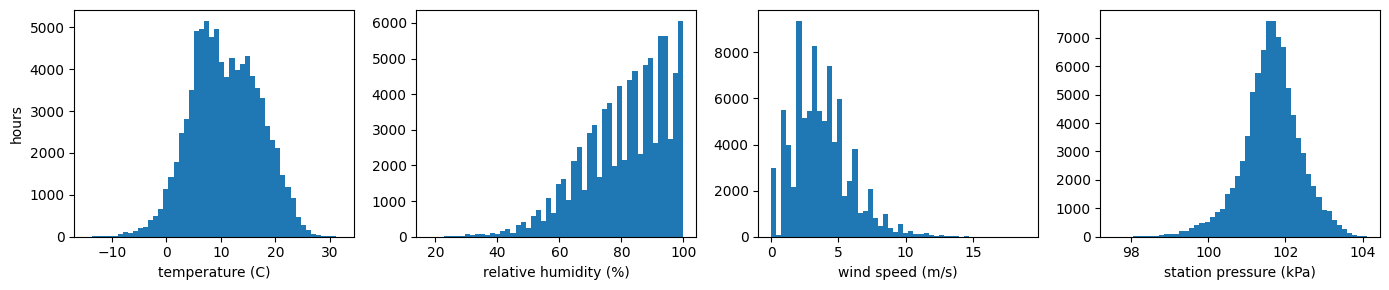

In [19]:
wx = pd.read_parquet(os.path.join(out_dir, "weather_yvr.parquet")).drop(columns="precip")

# 1. ranges: look for impossible values (humidity over 100, pressure far from about 101 kPa, huge wind speeds)
print(wx.describe().round(1).to_string())
print("\nshare of calm hours (wind speed 0):", round((wx["wspd"] == 0).mean() * 100, 1), "%")

# 2. distribution of each variable
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col, label in zip(axes, ["temp", "rh", "wspd", "press"], ["temperature (C)", "relative humidity (%)", "wind speed (m/s)", "station pressure (kPa)"]):
    ax.hist(wx[col].dropna(), bins=50)
    ax.set_xlabel(label)
axes[0].set_ylabel("hours")
plt.tight_layout()
plt.show()

hours matched: {'Clark Drive': 33875, 'Tsawwassen': 34451}

Spearman correlation with NO2, 2016-2019
              all hours            within hour           
station     Clark Drive Tsawwassen Clark Drive Tsawwassen
variable                                                 
humidity           0.22       0.28        0.19       0.23
pressure           0.03       0.19        0.03       0.19
temperature       -0.41      -0.33       -0.41      -0.30
wind speed        -0.30      -0.51       -0.30      -0.48

NO2 (ppb) by wind speed (m/s)
                 hours               mean_no2                vs_hour           
station    Clark Drive Tsawwassen Clark Drive Tsawwassen Clark Drive Tsawwassen
speed band                                                                     
calm              1197       1231        24.4       12.4         4.3        5.2
0.5-2             6213       6393        23.8       10.8         3.5        3.7
2-4              13373      13612        20.9        7.0      

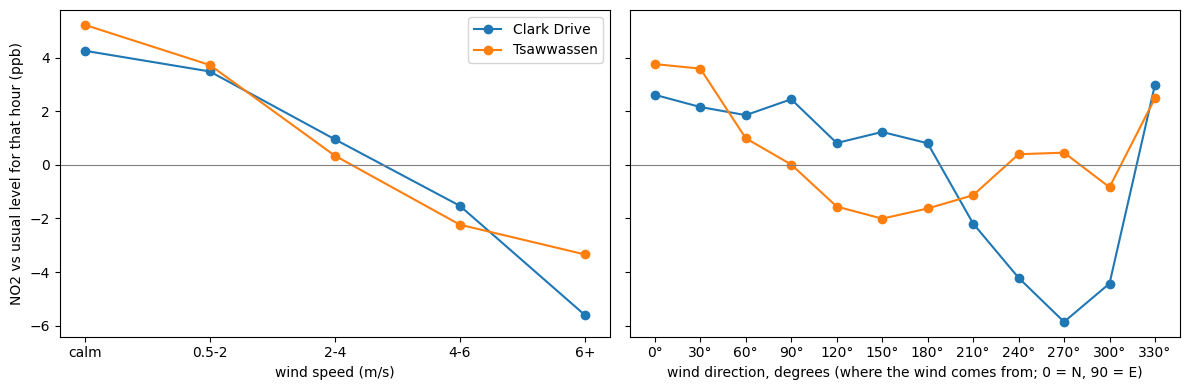

In [20]:
# YVR weather matched to each station's NO2 by hour, 2016-2019 (same normal period as the rest of the EDA)
wx = pd.read_parquet(os.path.join(out_dir, "weather_yvr.parquet")).drop(columns="precip")

# wind direction means nothing when there is no wind, so blank it out for calm hours
wx.loc[wx["wspd"] == 0, "wdir"] = np.nan

frames = []
for ems_id, name in stations.items():
    st_data = no2[(no2["EMS_ID"] == ems_id) & no2["year"].between(2016, 2019)][["start_local", "no2"]]
    m = st_data.merge(wx, on="start_local")
    m["station"] = name
    frames.append(m)
joined = pd.concat(frames, ignore_index=True)
joined["hour"] = joined["start_local"].dt.hour

# NO2 relative to the usual level for that station and hour of day,
# so a difference between bands is not just a difference in time of day
joined["no2_vs_hour"] = joined["no2"] - joined.groupby(["station", "hour"])["no2"].transform("mean")
print("hours matched:", joined.groupby("station").size().to_dict())

# 1. Spearman correlation of NO2 with each weather variable
# "all hours" uses every hour together; "within hour" is the correlation inside each hour of the day, averaged over the 24 hours
weather_cols = {"temp": "temperature", "rh": "humidity", "wspd": "wind speed", "press": "pressure"}
rows = []
for name, g in joined.groupby("station"):
    for col, label in weather_cols.items():
        overall = g["no2"].corr(g[col], method="spearman")
        by_hour = g.groupby("hour")[["no2", col]].apply(lambda h: h["no2"].corr(h[col], method="spearman"))
        rows.append({"station": name, "variable": label, "all hours": overall, "within hour": by_hour.mean()})
corr_table = pd.DataFrame(rows).pivot(index="variable", columns="station", values=["all hours", "within hour"]).round(2)
print("\nSpearman correlation with NO2, 2016-2019")
print(corr_table.to_string())

# 2. NO2 by band: hours in the band, mean NO2, and mean NO2 relative to the usual level for that hour
joined["speed band"] = pd.cut(joined["wspd"], [-0.1, 0.5, 2, 4, 6, 20], labels=["calm", "0.5-2", "2-4", "4-6", "6+"])
joined["temp band"] = pd.cut(joined["temp"], [-20, 0, 5, 10, 15, 20, 35], labels=["below 0", "0-5", "5-10", "10-15", "15-20", "20+"])
joined["rh band"] = pd.cut(joined["rh"], [0, 60, 70, 80, 90, 100], labels=["below 60", "60-70", "70-80", "80-90", "90-100"])
# 12 sectors of 30 degrees, labelled by their centre; ECCC's 10-degree steps put exactly 3 values in each
names = [f"{a}°" for a in range(0, 360, 30)]
joined["sector"] = ((joined["wdir"] / 30).round() % 12).map(dict(enumerate(names)))

def by_band(band_col, order=None):
    t = joined.groupby([band_col, "station"], observed=True).agg(hours=("no2", "size"), mean_no2=("no2", "mean"), vs_hour=("no2_vs_hour", "mean")).unstack("station")
    if order is not None:
        t = t.reindex(order)
    return t.round(1)

print("\nNO2 (ppb) by wind speed (m/s)")
print(by_band("speed band").to_string())
print("\nNO2 (ppb) by wind direction (where the wind comes from), calm hours left out")
print(by_band("sector", names).to_string())
print("\nNO2 (ppb) by temperature (C)")
print(by_band("temp band").to_string())
print("\nNO2 (ppb) by relative humidity (%)")
print(by_band("rh band").to_string())

# 3. figure: NO2 relative to the usual level for that hour, by wind speed and by wind direction
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for name in stations.values():
    s = joined[joined["station"] == name]
    speed = s.groupby("speed band", observed=True)["no2_vs_hour"].mean()
    axes[0].plot(speed.index.astype(str), speed.values, marker="o", label=name)
    direction = s.groupby("sector")["no2_vs_hour"].mean().reindex(names)
    axes[1].plot(names, direction.values, marker="o", label=name)
for ax in axes:
    ax.axhline(0, color="grey", linewidth=0.8)
axes[0].set_xlabel("wind speed (m/s)")
axes[1].set_xlabel("wind direction, degrees (where the wind comes from; 0 = N, 90 = E)")
axes[0].set_ylabel("NO2 vs usual level for that hour (ppb)")
axes[0].legend()
plt.tight_layout()
plt.show()

In [21]:
# rows kept for each variable, so a variable that lost every row shows up as 0
print(weather["variable"].value_counts().reindex(weather_vars, fill_value=0).to_string())

variable
TEMP_MEAN    360513
WSPD_SCLR    356735
WDIR_VECT    355558
HUMIDITY     272519
PRECIP            0
PRESSURE          0
